# Análise exploratória — Temperatura crítica de supercondutores

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from preparacao import carregar_dados_brutos, tratar_dados, colunas_elementos, nome_atributo, TEMPERATURA_NITROGENIO_LIQUIDO

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Carregamento e inspeção

In [2]:
atributos, composicao = carregar_dados_brutos()
print("train.csv:", atributos.shape)
print("unique_m.csv:", composicao.shape)

train.csv: (21263, 82)
unique_m.csv: (21263, 88)


In [3]:
atributos.head()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,wtd_std_atomic_mass,mean_fie,wtd_mean_fie,gmean_fie,wtd_gmean_fie,...,range_ThermalConductivity,wtd_range_ThermalConductivity,std_ThermalConductivity,wtd_std_ThermalConductivity,mean_Valence,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944,57.863,66.362,36.117,1.182,1.062,122.906,31.795,51.969,53.623,775.425,1010.269,718.153,938.017,...,399.973,57.128,168.854,138.517,2.250,2.257,2.213,2.220,1.369,1.066,1,1.086,0.433,0.437,29.000
1,5,92.729,58.518,73.133,36.397,1.449,1.058,122.906,36.162,47.095,53.980,766.440,1010.613,720.606,938.745,...,429.973,51.413,198.555,139.631,2.000,2.257,1.888,2.211,1.557,1.047,2,1.129,0.632,0.469,26.000
2,4,88.944,57.885,66.362,36.123,1.182,0.976,122.906,35.741,51.969,53.656,775.425,1010.820,718.153,939.009,...,399.973,57.128,168.854,138.541,2.250,2.271,2.213,2.233,1.369,1.029,1,1.114,0.433,0.445,19.000
3,4,88.944,57.874,66.362,36.120,1.182,1.022,122.906,33.768,51.969,53.639,775.425,1010.544,718.153,938.513,...,399.973,57.128,168.854,138.529,2.250,2.264,2.213,2.226,1.369,1.049,1,1.100,0.433,0.441,22.000
4,4,88.944,57.840,66.362,36.111,1.182,1.129,122.906,27.849,51.969,53.589,775.425,1009.717,718.153,937.026,...,399.973,57.128,168.854,138.494,2.250,2.243,2.213,2.207,1.369,1.096,1,1.057,0.433,0.429,23.000


In [4]:
composicao[['material', 'critical_temp']].head(10)

,material,critical_temp
0,Ba0.2La1.8Cu1O4,29.000
1,Ba0.1La1.9Ag0.1Cu0.9O4,26.000
2,Ba0.1La1.9Cu1O4,19.000
3,Ba0.15La1.85Cu1O4,22.000
4,Ba0.3La1.7Cu1O4,23.000
5,Ba0.5La1.5Cu1O4,23.000
6,Ba1La1Cu1O4,11.000
7,Sr0.1La1.9Cu1O4,33.000
8,Sr0.15La1.85Cu1O4,36.000
9,Sr0.2La1.8Cu1O4,31.000


In [5]:
atributos.dtypes.value_counts()

float64    79
int64       3
Name: count, dtype: int64

In [6]:
print("Tc igual nas duas bases, linha a linha:", (atributos["critical_temp"].values == composicao["critical_temp"].values).all())

Tc igual nas duas bases, linha a linha: True


## 2. Qualidade dos dados

In [7]:
print("Valores ausentes em train.csv:", atributos.isna().sum().sum())
print("Valores ausentes em unique_m.csv:", composicao.isna().sum().sum())
print("Valores negativos em train.csv:", (atributos < 0).sum().sum())

Valores ausentes em train.csv: 0
Valores ausentes em unique_m.csv: 0
Valores negativos em train.csv: 0


In [8]:
base_completa = pd.concat([atributos, composicao[["material"]]], axis=1)
print("Linhas totalmente duplicadas:", base_completa.duplicated().sum())
print("Materiais distintos:", base_completa["material"].nunique())
print("Linhas cujo material aparece mais de uma vez:", base_completa["material"].duplicated(keep=False).sum())

Linhas totalmente duplicadas: 0
Materiais distintos: 15542
Linhas cujo material aparece mais de uma vez: 7982


In [9]:
repetidos = base_completa[base_completa["material"].duplicated(keep=False)]
divergencia = (repetidos.groupby("material")["critical_temp"]
               .agg(medicoes="size", tc_min="min", tc_max="max", desvio="std")
               .sort_values("desvio", ascending=False))
divergencia.head(10)

,medicoes,tc_min,tc_max,desvio
material,,,,
H2S1,2,60.000,185.000,88.388
Tl1Ba2Cu1O5,2,15.000,95.000,56.569
Hg1Ba2Cu1O4.23,2,30.000,97.000,47.376
Tl1Ba1Sr1Ca1Cu2O7,2,16.000,80.000,45.255
Bi2Sr2Ca0.6Pr0.4Cu2O,2,25.000,81.600,40.022
Ca0.285Sr0.665Cu1O2,3,40.000,110.000,37.859
Y2Ba4Cu7O14,3,30.000,94.800,37.240
Tb1Sr2Cu2.7Mo0.3O7,2,29.800,80.000,35.497
Tl0.8Mo0.2Sr4Cu2Co3O7,2,30.000,80.000,35.355


In [10]:
atributos_sem_tc = atributos.columns.drop("critical_temp")
variacao_atributos = base_completa.groupby("material")[list(atributos_sem_tc)].nunique().max().max()
print("Máximo de valores distintos de um atributo dentro do mesmo material:", variacao_atributos)

Máximo de valores distintos de um atributo dentro do mesmo material: 1


In [11]:
print("Linhas duplicadas considerando só o train.csv:", atributos.duplicated().sum())
mesma_linha = atributos[atributos.duplicated(keep=False)].copy()
mesma_linha["material"] = composicao.loc[mesma_linha.index, "material"]
mesma_linha.groupby(list(atributos.columns))["material"].apply(lambda s: sorted(set(s))).head(5).reset_index(drop=True)

Linhas duplicadas considerando só o train.csv: 66


0    [Si0.25V0.75, Si1V3]
1    [Si0.25V0.75, Si1V3]
2    [Si0.25V0.75, Si1V3]
3    [Si0.25V0.75, Si1V3]
4      [B0.3Ru0.7, B3Ru7]
Name: material, dtype: object

## 3. Tratamento

In [12]:
dados, elementos = tratar_dados(atributos, composicao)
print("Antes:", len(atributos), "linhas  |  Depois:", len(dados), "linhas (uma por composição)")
dados[["material", "critical_temp", "qtd_medicoes", "amplitude_medicoes", "familia", "number_of_elements"]].head()

Antes: 21263 linhas  |  Depois: 15136 linhas (uma por composição)


,material,critical_temp,qtd_medicoes,amplitude_medicoes,familia,number_of_elements
0,Sn0.92Ag0.05Te1,1.660,1,0.000,Outros,3
1,Sn0.9Ag0.07Te1,1.730,1,0.000,Outros,3
2,Ag0.035Cd0.01Sn0.955,3.650,1,0.000,Outros,3
3,Ag0.03Tl0.97,2.670,1,0.000,Outros,2
4,Sn0.87Ag0.1Te1,1.830,2,0.100,Outros,3


In [13]:
comparacao = pd.DataFrame({
    "original": atributos["critical_temp"].describe(),
    "tratado": dados["critical_temp"].describe(),
})
comparacao

,original,tratado
count,21263.000,15136.000
mean,34.421,33.589
std,34.254,33.858
min,0.000,0.000
25%,5.365,5.000
50%,20.000,19.000
75%,63.000,61.000
max,185.000,143.000


## 4. Estatística descritiva da temperatura crítica (Tc)

In [14]:
tc = dados["critical_temp"]
resumo_tc = pd.Series({
    "média": tc.mean(),
    "mediana": tc.median(),
    "moda (arredondada)": tc.round().mode()[0],
    "desvio padrão": tc.std(),
    "coef. de variação (%)": tc.std() / tc.mean() * 100,
    "mínimo": tc.min(),
    "Q1": tc.quantile(0.25),
    "Q3": tc.quantile(0.75),
    "IQR": tc.quantile(0.75) - tc.quantile(0.25),
    "máximo": tc.max(),
    "assimetria": tc.skew(),
    "curtose": tc.kurt(),
})
resumo_tc

média                    33.589
mediana                  19.000
moda (arredondada)        2.000
desvio padrão            33.858
coef. de variação (%)   100.802
mínimo                    0.000
Q1                        5.000
Q3                       61.000
IQR                      56.000
máximo                  143.000
assimetria                0.885
curtose                  -0.484
dtype: float64

C:\Users\T-GAMER\AppData\Local\Temp\ipykernel_21260\881605929.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eixos[1].boxplot(tc, vert=False)


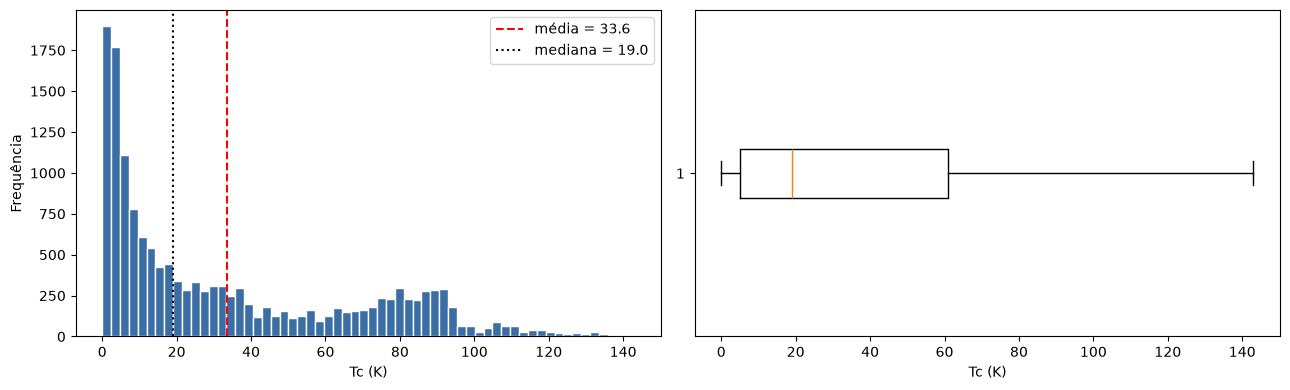

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].hist(tc, bins=60, color="#3b6ea5", edgecolor="white")
eixos[0].axvline(tc.mean(), color="red", linestyle="--", label=f"média = {tc.mean():.1f}")
eixos[0].axvline(tc.median(), color="black", linestyle=":", label=f"mediana = {tc.median():.1f}")
eixos[0].set_xlabel("Tc (K)"); eixos[0].set_ylabel("Frequência"); eixos[0].legend()
eixos[1].boxplot(tc, vert=False)
eixos[1].set_xlabel("Tc (K)")
plt.tight_layout(); plt.show()

## 5. Valores atípicos (critério do IQR)

In [16]:
q1, q3 = tc.quantile([0.25, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
limite_inferior = q1 - 1.5 * iqr
print(f"Limites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
dados.loc[(tc > limite_superior) | (tc < limite_inferior), ["material", "critical_temp", "qtd_medicoes", "amplitude_medicoes"]]

Limites: [-79.00, 145.00]


,material,critical_temp,qtd_medicoes,amplitude_medicoes


In [17]:
outliers_por_coluna = {}
for coluna in atributos_sem_tc:
    serie = dados[coluna]
    a, b = serie.quantile([0.25, 0.75])
    faixa = b - a
    outliers_por_coluna[nome_atributo(coluna)] = ((serie < a - 1.5 * faixa) | (serie > b + 1.5 * faixa)).mean() * 100
pd.Series(outliers_por_coluna, name="% de outliers").sort_values(ascending=False).head(10)

Desvio padrão — Densidade                            16.094
Média geométrica — Massa atômica                     14.535
Entropia ponderada — Afinidade eletrônica            13.577
Amplitude — Densidade                                12.632
Desvio padrão ponderado — Calor de fusão             11.668
Desvio padrão — Afinidade eletrônica                 11.291
Entropia ponderada — Primeira energia de ionização   10.518
Média — Afinidade eletrônica                         10.115
Desvio padrão ponderado — Densidade                   9.983
Amplitude — Calor de fusão                            9.798
Name: % de outliers, dtype: float64

## 6. Tc por família de material

In [18]:
dados.groupby("familia", observed=True)["critical_temp"].agg(["count", "mean", "median", "std", "min", "max"])

,count,mean,median,std,min,max
familia,,,,,,
Cuprato,7489,58.719,61.600,30.932,0.001,143.000
Base de ferro,1232,21.160,19.000,12.481,0.200,61.400
Outros,6415,6.637,4.200,8.038,0.000,122.500


In [19]:
pd.crosstab(dados["familia"], dados["acima_77k"], normalize="index").mul(100).round(1)

acima_77k,Tc < 77 K,Tc ≥ 77 K
familia,,
Cuprato,64.700,35.300
Base de ferro,100.000,0.000
Outros,99.800,0.200


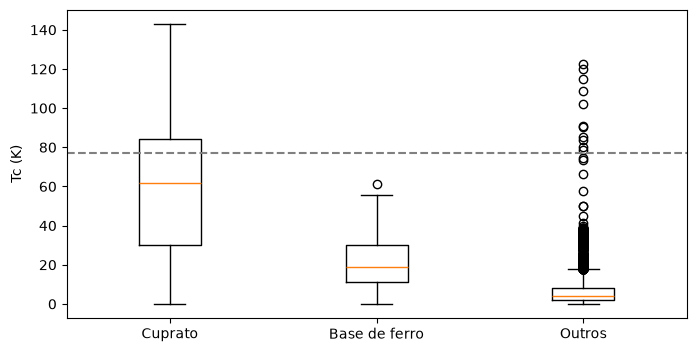

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
grupos = [g["critical_temp"].values for _, g in dados.groupby("familia", observed=True)]
ax.boxplot(grupos, tick_labels=dados["familia"].cat.categories)
ax.axhline(TEMPERATURA_NITROGENIO_LIQUIDO, color="gray", linestyle="--")
ax.set_ylabel("Tc (K)")
plt.show()

## 7. Tc por número de elementos

In [21]:
dados.groupby("number_of_elements")["critical_temp"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
number_of_elements,,,,
1,52,4.016,2.925,4.374
2,2212,4.442,3.415,5.088
3,2870,9.102,5.680,10.676
4,2597,28.077,16.750,29.896
5,4336,48.795,43.950,32.077
6,2270,58.802,61.550,31.777
7,725,66.313,67.000,31.363
8,60,86.043,96.400,27.587
9,14,73.229,74.825,14.381


## 8. Correlações com Tc

In [22]:
numericas = list(atributos_sem_tc) + ["critical_temp"]
pearson = dados[numericas].corr(method="pearson")["critical_temp"].drop("critical_temp")
spearman = dados[numericas].corr(method="spearman")["critical_temp"].drop("critical_temp")
tabela_corr = pd.DataFrame({"pearson": pearson, "spearman": spearman})
tabela_corr.index = [nome_atributo(c) for c in tabela_corr.index]
tabela_corr.sort_values("pearson", key=abs, ascending=False).head(15)

,pearson,spearman
Desvio padrão ponderado — Condutividade térmica,0.717,0.711
Amplitude — Condutividade térmica,0.685,0.721
Amplitude — Raio atômico,0.655,0.758
Desvio padrão — Condutividade térmica,0.645,0.611
Média ponderada — Valência,-0.634,-0.738
Entropia ponderada — Massa atômica,0.631,0.715
Número de elementos,0.628,0.700
Entropia — Valência,0.625,0.715
Média geométrica ponderada — Valência,-0.618,-0.738
Amplitude — Primeira energia de ionização,0.611,0.673


In [23]:
tabela_corr.sort_values("pearson").head(8)

,pearson,spearman
Média ponderada — Valência,-0.634,-0.738
Média geométrica ponderada — Valência,-0.618,-0.738
Média — Valência,-0.599,-0.685
Média geométrica — Valência,-0.575,-0.666
Média geométrica — Densidade,-0.545,-0.598
Média geométrica ponderada — Densidade,-0.543,-0.606
Amplitude ponderada — Valência,-0.467,-0.525
Média geométrica ponderada — Calor de fusão,-0.457,-0.536


In [24]:
escolhidas = ["wtd_std_ThermalConductivity", "range_atomic_radius", "number_of_elements", "wtd_mean_Valence", "gmean_Density", "wtd_gmean_Valence", "mean_Valence"]
matriz = dados[escolhidas].corr()
matriz.index = matriz.columns = [nome_atributo(c) for c in escolhidas]
matriz.round(2)

,Desvio padrão ponderado — Condutividade térmica,Amplitude — Raio atômico,Número de elementos,Média ponderada — Valência,Média geométrica — Densidade,Média geométrica ponderada — Valência,Média — Valência
Desvio padrão ponderado — Condutividade térmica,1.000,0.740,0.680,-0.750,-0.610,-0.730,-0.690
Amplitude — Raio atômico,0.740,1.000,0.780,-0.770,-0.830,-0.770,-0.760
Número de elementos,0.680,0.780,1.000,-0.670,-0.650,-0.680,-0.630
Média ponderada — Valência,-0.750,-0.770,-0.670,1.000,0.780,1.000,0.930
Média geométrica — Densidade,-0.610,-0.830,-0.650,0.780,1.000,0.800,0.820
Média geométrica ponderada — Valência,-0.730,-0.770,-0.680,1.000,0.800,1.000,0.940
Média — Valência,-0.690,-0.760,-0.630,0.930,0.820,0.940,1.000


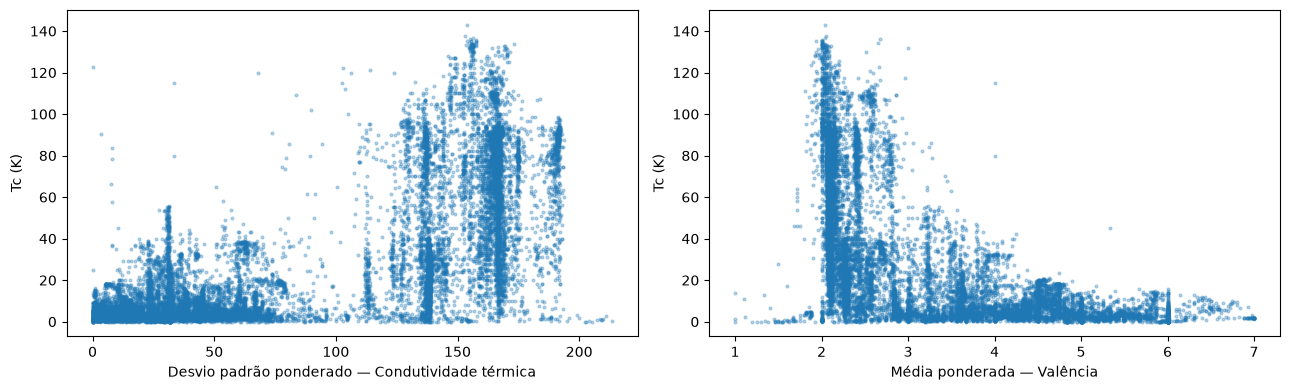

In [25]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for ax, coluna in zip(eixos, ["wtd_std_ThermalConductivity", "wtd_mean_Valence"]):
    ax.scatter(dados[coluna], dados["critical_temp"], s=4, alpha=0.3)
    ax.set_xlabel(nome_atributo(coluna)); ax.set_ylabel("Tc (K)")
plt.tight_layout(); plt.show()

## 9. Composição química

In [26]:
presenca = dados[elementos] > 0
frequencia = presenca.sum().sort_values(ascending=False)
frequentes = frequencia[frequencia >= 300].index
linhas = []
for el in frequentes:
    com = dados.loc[presenca[el], "critical_temp"]
    sem = dados.loc[~presenca[el], "critical_temp"]
    linhas.append({"elemento": el, "materiais": len(com), "mediana_com": com.median(), "mediana_sem": sem.median(), "diferenca": com.median() - sem.median()})
tabela_elementos = pd.DataFrame(linhas).sort_values("diferenca", ascending=False)
tabela_elementos

,elemento,materiais,mediana_com,mediana_sem,diferenca
24,Hg,610,83.000,17.826,65.174
4,Ca,3269,74.000,11.600,62.400
2,Ba,4687,69.000,9.260,59.740
1,Cu,7728,59.550,5.400,54.150
19,Tl,697,71.000,17.980,53.020
0,O,8435,53.000,4.820,48.180
5,Y,2823,61.000,13.800,47.200
3,Sr,3647,42.400,11.500,30.900
8,Bi,1710,47.350,17.200,30.150
27,Gd,521,40.000,18.200,21.800


## 10. Exportação da base tratada

In [27]:
colunas_saida = ["material", "critical_temp", "qtd_medicoes", "amplitude_medicoes", "familia", "acima_77k"] + list(atributos_sem_tc)
dados[colunas_saida].to_csv("dados/dados_tratados.csv", index=False)
print("Arquivo salvo:", dados[colunas_saida].shape)

Arquivo salvo: (15136, 87)
